# Deep Learning Frameworks

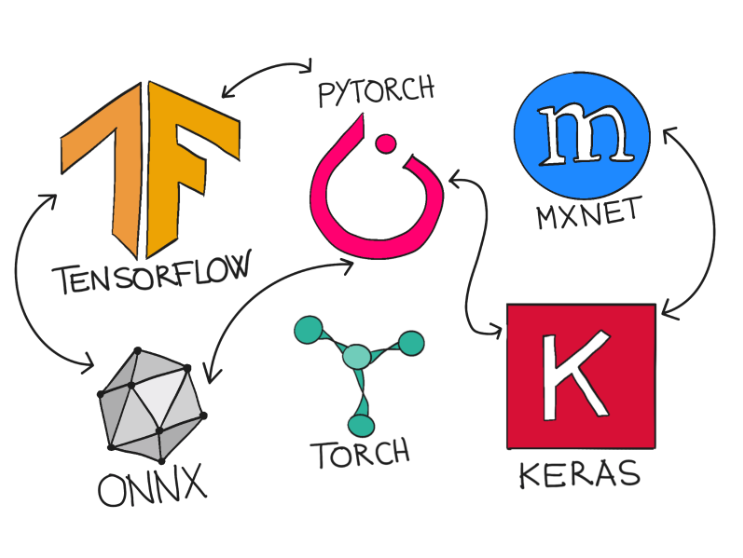

# Introduction to PyTorch
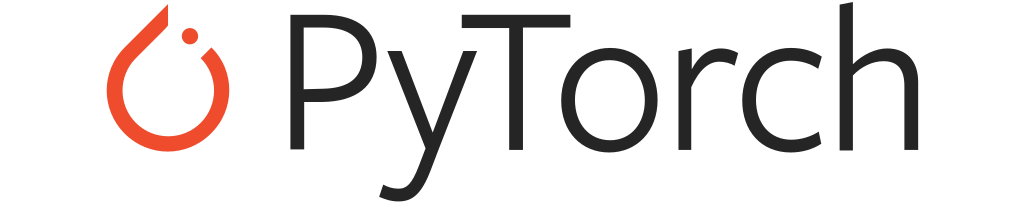
## Installation
https://pytorch.org/get-started/locally/

## Hardware acceleration

CPU and NVIDIA (CUDA): [Standard installation](https://pytorch.org/get-started/locally/)  
Mac's M chips: [PyTorch installation for Mac's M chipsets](https://developer.apple.com/metal/pytorch/)

---
## Getting started

PyTorch is simply known as torch in Python.

In [ ]:
import torch
import numpy as np # Numpy is just for example purposes. Not needed to use torch

### Working with tensors

"Tensor" is a generalization vector / matrix. PyTorch always refers to data as tensors

In [ ]:
data = [[1, 2],[3, 4]] # Just some data
x_data = torch.tensor(data) # Convert to tensor
x_data.size() # Check size of tensor. Analogous to .shape from numpy

外層：torch.tensor(...) 回傳的物件，它的 Python class 永遠是 torch.Tensor。不管裡面裝什麼、幾維，type() 都是這個。

內層：元素的 dtype 只能是 PyTorch 自己定義的一組數值型別，不是任意 Python type。可用的大致是：

浮點	float32(預設)、float64、float16、bfloat16

整數	int8、int16、int32、int64(預設)、uint8

In [ ]:
torch.backends.mps.is_available()   # 應該是 True
torch.backends.mps.is_built()       # 確認這個 build 有編進 MPS

In [ ]:
# 這邊確認過，沒辦法cuda

x_data.to('mps')

Create a torch tensor from a numpy array.

In [ ]:
np_array = np.array(data) # Create numpy array
x_np = torch.from_numpy(np_array) # Create tensor from numpy
x_np

Create a tensor of random data given a specific size.

In [ ]:
x_rand = torch.rand(4, 2)
x_rand

---
### Tensor operations

Operations between tensors are straightforward. However, ensure that shapes match!

Element-wise operations

In [ ]:
a = torch.tensor([1.0, 2.0])
b = torch.tensor([3.0, 4.0])

# Element-wise operations
print("a + b:", a + b)
print("a * b:", a * b)

Matrix multiplication. `torch.matmul()` is the standard matrix multiplication function. `A @ B` is a shorthand for `torch.matmul()`.

In [ ]:
A = torch.rand(2, 3)
B = torch.rand(3, 2)

# Matrix multiplication
print("Matrix multiplication result:\n", torch.matmul(A, B))
print("Shorthand matrix multiplication result:\n", A @ B)

### Indexing and slicing
Indexing and slicing in PyTorch is similar to numpy.

In [ ]:
# x_ones = torch.ones(4, 4)
x_ones = torch.rand(4, 4)
print(x_ones)

first_row = x_ones[1]
last_row = x_ones[-1]
first_column = x_ones[:, 0]
last_column = x_ones[:, -1]

print(f"First row: {first_row}", end="\n\n") # Get the first row
print(f"First column: {first_column}", end="\n\n") # Get the first column
print(f"Last column: {last_column}", end="\n\n") # Get the last column

x_ones[:,1] = 0 # Set the second column (index 1) to all zeroes
print(f"Column values set to 0's{x_ones}", end="\n\n")

---
### Using accelerator (such as GPU)
Torch requires that all tensors are on the same device in order to perform operations.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps") # CUDA is NVIDIA's platform for GPU acceleration

x = torch.rand(2, 2).to(device) # Move tensor to device
print(f"Tensor on {device}: {x}")

To perform any operation between tensors, all tensors must be on the same device. This example uses `meta` device, which is only used here for example purposes. If you use hardware acceleration, you should have either `cuda` or `mps` available.

In [ ]:
xa = torch.rand(2, 2).to("meta") # You will likely never use 'meta'. 'meta' is used for testing only for the example.
# xa = torch.rand(2, 2).to("cuda") # For NVIDIA's CUDA
# xa = torch.rand(2, 2).to("mps") # For Mac's M chips
print(f"Tensor on {xa.device}: {xa}")
xa + x # Will produce an error

You can also move a tensor to the same device as another tensor by using `x.device`, where `x` is already defined.

In [ ]:
xb = torch.rand(2, 2)
xb = xb.to(device=x.device)
x + xb

## Differentiation

PyTorch can perform automatic differentiation!

$$\frac{dy}{dx}$$  

PyTorch enables automatic differentiation. By defining a tensor `x` and setting `requires_grad=True`, you tell torch that the differentiation should happen with respect to `x`. Therefore, when you call `y.backward()`, torch automatically computes the gradient `x.grad`.

In [ ]:
x = torch.tensor(2.0, requires_grad=True)

y = 2 * x**2  + 2 * x**3  # y = 2x² + 2x³
# 這行看起來只是算出一個數值，但 PyTorch 在背後同時建了一張運算圖（computational graph）：記錄了 x 先被平方、乘 2、x 再被三次方、乘 2、最後相加。每一步都知道自己的微分規則。

y.backward()  # Calculate the gradient (dy/dx)

print(f"dy/dx at x=2: {x.grad}")  # Output: 32

In [ ]:
y.grad_fn 

This is identical to manually differentiating as shown here using `sympy`.

In [ ]:
import sympy as sp
x = sp.symbols('x')
f = 2*x**2 + 2*x**3
f_prime = sp.diff(f, x)
f_prime

In [ ]:
x = 2.0
6*x**2 + 4*x # 6x²+4x

In [ ]:
x = torch.tensor(5.0, requires_grad=True)   # 未知數，隨便給個起點

for i in range(30):
    y = 2 * x**2 + 2 * x**3 + 10          # 想找讓 y 最小的 x
    y.backward()
    with torch.no_grad():
        x -= 0.01 * x.grad                 # 往下坡走一步
    x.grad.zero_()                         # 清掉累積的梯度

print(x)

---
### Differentiation on model parameters

In the context of neural networks, differentiation is performed with respect to the model parameters, i.e., the weights and biases. You will often see `nn.Linear()` being used for simple neural networks.

In [ ]:
import torch.nn as nn

# Simple linear model: y = wx + b
model = nn.Linear(in_features=1, out_features=1)

x = torch.tensor([[1.0], [2.0], [3.0]])
y = torch.tensor([[0.5], [1.0], [1.5]])

pred = model(x)
loss = torch.sum((y - pred) ** 2)
loss.backward()

for name, param in model.named_parameters():
    print(f"{name}: {param.grad}")

## Neural network example

### Import packages

In [ ]:
import torch
from torch import nn

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles

### Get data
For this example, we generate a simple dataset using `sklearn.datasets.make_circles()`.

In [62]:
# Make 1000 samples 
n_samples = 10000000

# Create circles
X, y = make_circles(n_samples,
                    noise=0.1, # a little bit of noise to the dots
                    random_state=42) # keep random state so we get the same values

print(f"First 3 X features:\n{X[:3]}")
print(f"First 3 y labels:\n{y[:3]}")
print(f"\nType of X: {type(X)}")
print(f"Type of y: {type(y)}")

First 3 X features:
[[ 0.23830137  0.87906093]
 [ 0.6390211  -0.61554117]
 [-0.30786712  0.8042226 ]]
First 3 y labels:
[0 1 1]

Type of X: <class 'numpy.ndarray'>
Type of y: <class 'numpy.ndarray'>


#### Plot data

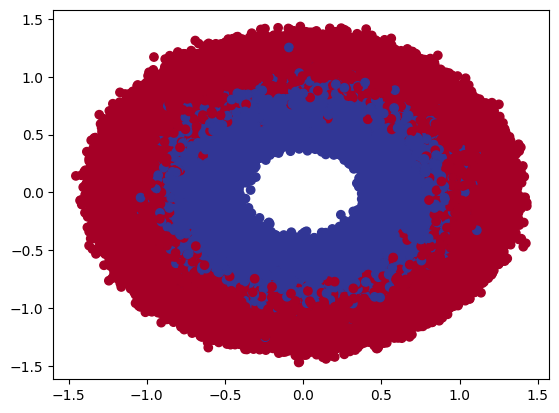

In [63]:
plt.scatter(x=X[:, 0],
            y=X[:, 1],
            c=y,
            cmap=plt.cm.RdYlBu)
plt.show()

In [ ]:
# Save the dataset
# data = pd.DataFrame({"X0": X[:, 0], # First feature
#                      "X1": X[:, 1], # Second feature
#                      "label": y})  # Target label (0 or 1)
# data.to_csv("concentric.csv", index=False)

#### Prepare data for torch

PyTorch requires `torch.tensor` types to perform its operations.

In [71]:
X_train = torch.from_numpy(X).float()
y_train = torch.from_numpy(y).float()
X_train

tensor([[ 0.2383,  0.8791],
        [ 0.6390, -0.6155],
        [-0.3079,  0.8042],
        ...,
        [ 0.5788, -0.8510],
        [-0.3716,  0.7000],
        [-0.2615,  0.8816]])

### Define model
This definition of a model is a typical setup. Define the model layout in the `__init__()` method. The `forward()` must be created and is called when data is passed to a model, e.g., `model = SomeModel(); model(X);` calls `forward()`.

In [72]:
class SomeModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.a_model_definition = nn.Sequential(
            nn.Linear(in_features=2, out_features=8), # takes in 2 features (X), produces 8 features
            nn.ReLU(),
            nn.Linear(in_features=8, out_features=1),
            nn.Sigmoid(), # Activation function typically used for binary classification on the output
        )

    def forward(self, x):
        return self.a_model_definition(x) # Passes data through the model

### Standard setup and loop
Before training, we need to define a loss function, an optimizer, and ensure that all tensors and the model are on the same device.

In [73]:
def accuracy(y_true, y_pred):
    return (y_true == y_pred).float().sum() / y_true.size(0) * 100

model = SomeModel() # Create a model using the definition from above

# Make sure everything is on the same device
device = "cuda" if torch.cuda.is_available() else "mps" # Define the device. Use CUDA if available.

model = model.to(device=device)
X_train = X_train.to(device=device)
y_train = y_train.to(device=device)

loss_fn = nn.BCELoss() # Binary cross-entropy loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # Basic stochastic gradient descent

This is a typical training loop. The output of `model(X_train)` are the predictions.  

`optimizer.zero_grad()` resets any gradients from previous iterations.  
`loss.backward()` performs automatic differentiation using the chain rule.  
`optimizer.step()` performs parameter updates, i.e., for model $f$ and input $x$,  
the step is: $\quad x - \nabla f(x)$.

In [75]:
model.train()
# Training loop
for epoch in range(10000):
    pred = model(X_train)  # Forward pass
    pred = pred.squeeze() # Converts size from (800, 1) to (800)
    
    loss = loss_fn(pred, y_train)  # Compute loss
    acc = accuracy(y_train, torch.round(pred))
    
    optimizer.zero_grad()  # Zero gradients
    loss.backward()  # Backpropagation
    optimizer.step()  # Update weights

    if epoch % 100 == 0:
        print(f"Epoch {epoch:<4} | loss={loss.item():.4f} | accuracy={acc.item():.2f}")

Epoch 0    | loss=0.6873 | accuracy=54.37
Epoch 100  | loss=0.6815 | accuracy=56.18
Epoch 200  | loss=0.6730 | accuracy=62.43
Epoch 300  | loss=0.6624 | accuracy=64.60
Epoch 400  | loss=0.6487 | accuracy=69.30
Epoch 500  | loss=0.6330 | accuracy=72.60
Epoch 600  | loss=0.6162 | accuracy=73.95
Epoch 700  | loss=0.5978 | accuracy=75.63
Epoch 800  | loss=0.5789 | accuracy=76.85
Epoch 900  | loss=0.5605 | accuracy=77.98
Epoch 1000 | loss=0.5428 | accuracy=79.01
Epoch 1100 | loss=0.5261 | accuracy=79.84
Epoch 1200 | loss=0.5105 | accuracy=80.50
Epoch 1300 | loss=0.4961 | accuracy=81.03
Epoch 1400 | loss=0.4829 | accuracy=81.45
Epoch 1500 | loss=0.4708 | accuracy=81.79
Epoch 1600 | loss=0.4597 | accuracy=82.07
Epoch 1700 | loss=0.4496 | accuracy=82.30
Epoch 1800 | loss=0.4405 | accuracy=82.49
Epoch 1900 | loss=0.4323 | accuracy=82.64
Epoch 2000 | loss=0.4248 | accuracy=82.77
Epoch 2100 | loss=0.4181 | accuracy=82.88
Epoch 2200 | loss=0.4122 | accuracy=82.97
Epoch 2300 | loss=0.4068 | accurac

KeyboardInterrupt: 

### Tensorflow Examples

Just for contrast, here is the Tensorflow equivalent of the PyTorch code. The interface pattern may look friendlier, but is really just making it more difficult to customise.

```python
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Dense(8, activation="relu", input_shape=(2,)),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer="adam", loss="binary_crossentropy")
model.fit(X_train, y_train, epochs=1000)
```

In [70]:
import time

def run(device, epochs=2000):
    torch.manual_seed(42)
    m = SomeModel().to(device)
    xb, yb = X_train.to(device), y_train.to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.001)
    fn = nn.BCELoss()
    # 暖機：第一次呼叫會編譯 kernel，不算進去
    for _ in range(10):
        loss = fn(m(xb).squeeze(), yb); opt.zero_grad(); loss.backward(); opt.step()
    if device == "mps":
        torch.mps.synchronize()
    t = time.perf_counter()
    for _ in range(epochs):
        loss = fn(m(xb).squeeze(), yb); opt.zero_grad(); loss.backward(); opt.step()
    if device == "mps":
        torch.mps.synchronize()
    return time.perf_counter() - t

print("cpu:", run("cpu"))
print("mps:", run("mps"))

# cpu: 396.1255669999955
# mps: 217.08843658400292

cpu: 396.1255669999955
mps: 217.08843658400292
